PART 3: Data Analysis Pandas and NumPy 

3.1: Import libraries and load the dataset

In [15]:
import micropip
await micropip.install("seaborn")

In [16]:
import micropip
await micropip.install("openpyxl")

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [18]:
file_path = "otp_time_series_master_current_10.xlsx"

excel_file = pd.ExcelFile(file_path)

sheets = []

for sheet in excel_file.sheet_names:
    data = pd.read_excel(file_path, sheet_name=sheet)
    data["Source Sheet"] = sheet
    sheets.append(data)

df = pd.concat(sheets, ignore_index=True)

print(df.head())

                 Route Departing Port Arriving Port  Airline      Month  \
0    Adelaide-Brisbane       Adelaide      Brisbane  Jetstar 2023-01-01   
1  Adelaide-Gold Coast       Adelaide    Gold Coast  Jetstar 2023-01-01   
2   Adelaide-Melbourne       Adelaide     Melbourne  Jetstar 2023-01-01   
3       Adelaide-Perth       Adelaide         Perth  Jetstar 2023-01-01   
4      Adelaide-Sydney       Adelaide        Sydney  Jetstar 2023-01-01   

   Sectors Scheduled  Sectors Flown  Cancellations  Departures On Time  \
0               32.0           30.0            2.0                20.0   
1               31.0           31.0            0.0                25.0   
2              111.0          103.0            8.0                54.0   
3               31.0           29.0            2.0                26.0   
4              122.0          108.0           14.0                91.0   

   Arrivals On Time  Departures Delayed  Arrivals Delayed  \
0              21.0                10.0    

Explanation:
- Pandas is used to load and organize the dataset.
- NumPy is used for numerical calculations.
- Matplotlib and Seaborn are used to create visualizations.
- All Excel sheets are combined into one dataset for analysis.

3.2: Prepare the dataset for analysis

In [19]:
# Create a copy of the dataset
analysis_df = df.copy()

# Remove unnecessary spaces
analysis_df.columns = analysis_df.columns.str.strip()

# Convert Month into datetime format
analysis_df["Month"] = pd.to_datetime(
    analysis_df["Month"], errors="coerce"
)

# Clean categorical columns
for col in ["Airline", "Route",
            "Departing Port", "Arriving Port"]:
    analysis_df[col] = (
        analysis_df[col].astype("string").str.strip()
    )

# Convert numerical columns
count_columns = [
    "Sectors Scheduled",
    "Sectors Flown",
    "Cancellations",
    "Departures On Time",
    "Arrivals On Time",
    "Departures Delayed",
    "Arrivals Delayed"
]

for col in count_columns:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col], errors="coerce"
    )

# Exclude aggregate airline records
analysis_df = analysis_df[
    (analysis_df["Airline"].str.casefold() != "all airlines")
    & analysis_df["Airline"].notna()
    & analysis_df["Month"].notna()
].copy()

# Calculate performance rates
analysis_df["Departure On-Time Rate (%)"] = (
    analysis_df["Departures On Time"]
    / analysis_df["Sectors Flown"].replace(0, np.nan)
) * 100

analysis_df["Arrival On-Time Rate (%)"] = (
    analysis_df["Arrivals On Time"]
    / analysis_df["Sectors Flown"].replace(0, np.nan)
) * 100

analysis_df["Cancellation Rate (%)"] = (
    analysis_df["Cancellations"]
    / analysis_df["Sectors Scheduled"].replace(0, np.nan)
) * 100

analysis_df["Departure Delay Rate (%)"] = (
    analysis_df["Departures Delayed"]
    / analysis_df["Sectors Flown"].replace(0, np.nan)
) * 100

# Extract year
analysis_df["Year"] = analysis_df["Month"].dt.year

print("Dataset prepared successfully!")
print("Rows:", len(analysis_df))

analysis_df.head()

Dataset prepared successfully!
Rows: 71631


,Route,Departing Port,Arriving Port,Airline,Month,Sectors Scheduled,Sectors Flown,Cancellations,Departures On Time,Arrivals On Time,...,Arrivals Delayed,OnTime Departures \n(%),OnTime Arrivals \n(%),Cancellations \n\n(%),Source Sheet,Departure On-Time Rate (%),Arrival On-Time Rate (%),Cancellation Rate (%),Departure Delay Rate (%),Year
0,Adelaide-Brisbane,Adelaide,Brisbane,Jetstar,2023-01-01,32.0,30.0,2.0,20.0,21.0,...,9.0,66.666667,70.0,6.250000,2023-26 OTP,66.666667,70.000000,6.250000,33.333333,2023
1,Adelaide-Gold Coast,Adelaide,Gold Coast,Jetstar,2023-01-01,31.0,31.0,0.0,25.0,25.0,...,6.0,80.645161,80.645161,0.000000,2023-26 OTP,80.645161,80.645161,0.000000,19.354839,2023
2,Adelaide-Melbourne,Adelaide,Melbourne,Jetstar,2023-01-01,111.0,103.0,8.0,54.0,64.0,...,39.0,52.427184,62.135922,7.207207,2023-26 OTP,52.427184,62.135922,7.207207,47.572816,2023
3,Adelaide-Perth,Adelaide,Perth,Jetstar,2023-01-01,31.0,29.0,2.0,26.0,28.0,...,1.0,89.655172,96.551724,6.451613,2023-26 OTP,89.655172,96.551724,6.451613,10.344828,2023
4,Adelaide-Sydney,Adelaide,Sydney,Jetstar,2023-01-01,122.0,108.0,14.0,91.0,87.0,...,21.0,84.259259,80.555556,11.475410,2023-26 OTP,84.259259,80.555556,11.475410,15.740741,2023


Explanation:

We calculate the on-time, delay and cancellation percentages using the original flight counts. This gives weighted rates based on actual flight activity instead of simply averaging percentages.

3.3: Pandas Filtering and Sorting

In [20]:
# Select the latest available year
latest_year = analysis_df["Year"].max()

latest_data = analysis_df[
    analysis_df["Year"] == latest_year
]

# Filter records with flights
latest_data = latest_data[
    latest_data["Sectors Flown"] > 0
]

# Sort by number of flights
sorted_data = latest_data.sort_values(
    by="Sectors Flown",
    ascending=False
)

# Display top 10 records
sorted_data[
    ["Airline", "Route", "Sectors Flown",
     "Departures Delayed"]
].head(10)

,Airline,Route,Sectors Flown,Departures Delayed
18602,QantasLink,All Ports-All Ports,12572.0,2183.0
20480,QantasLink,All Ports-All Ports,12505.0,2427.0
20945,QantasLink,All Ports-All Ports,12310.0,2115.0
21412,QantasLink,All Ports-All Ports,12283.0,2160.0
19071,QantasLink,All Ports-All Ports,12197.0,1810.0
20601,Virgin Australia,All Ports-All Ports,12097.0,2763.0
19544,QantasLink,All Ports-All Ports,12075.0,1943.0
18723,Virgin Australia,All Ports-All Ports,12071.0,2563.0
17785,Virgin Australia,All Ports-All Ports,11991.0,2072.0
19192,Virgin Australia,All Ports-All Ports,11770.0,1930.0


Interpretation:

This analysis identifies the airline-route combinations with the highest flight activity in the latest available year. It helps identify which operations account for a larger share of airline activity.

3.4: Grouped Analysis 1 – Airline Performance

In [21]:
airline_analysis = analysis_df.groupby(
    "Airline"
).agg({
    "Sectors Scheduled": "sum",
    "Sectors Flown": "sum",
    "Cancellations": "sum",
    "Departures On Time": "sum",
    "Departures Delayed": "sum",
    "Arrivals On Time": "sum",
    "Arrivals Delayed": "sum"
}).reset_index()

# Calculate airline punctuality
airline_analysis["Departure On-Time Rate (%)"] = (
    airline_analysis["Departures On Time"]
    / airline_analysis["Sectors Flown"].replace(0, np.nan)
) * 100

airline_analysis["Cancellation Rate (%)"] = (
    airline_analysis["Cancellations"]
    / airline_analysis["Sectors Scheduled"].replace(0, np.nan)
) * 100

# Sort airlines by punctuality
airline_analysis = airline_analysis.sort_values(
    by="Departure On-Time Rate (%)",
    ascending=False
)

display(airline_analysis.round(2))

,Airline,Sectors Scheduled,Sectors Flown,Cancellations,Departures On Time,Departures Delayed,Arrivals On Time,Arrivals Delayed,Departure On-Time Rate (%),Cancellation Rate (%)
1,Hinterland,44401.0,44024.0,377.0,40991.00,3033.00,39296.00,4728.00,93.11,0.85
5,Regional Express,935046.0,925670.0,9376.0,799954.00,125716.00,771796.00,153874.00,86.42,1.00
3,Qantas,3297223.0,3212474.0,84749.0,2658669.00,553805.00,2619960.00,592514.00,82.76,2.57
12,Virgin Australia Regional Airlines,258812.0,253343.0,5469.0,207050.00,46293.00,202863.00,50480.00,81.73,2.11
7,Skytrans Australia,22468.0,20961.0,1507.0,17067.00,3915.00,16966.00,4016.00,81.42,6.71
8,Skywest,44807.0,44651.0,156.0,36232.00,8419.00,35304.00,9347.00,81.14,0.35
11,Virgin Australia - ATR/F100 Operations,44226.0,43264.0,962.0,35045.00,8219.00,33235.00,10029.00,81.00,2.18
4,QantasLink,3261692.0,3160184.0,101508.0,2551528.00,608656.00,2512106.00,648078.00,80.74,3.11
10,Virgin Australia,4240686.0,4132860.0,107826.0,3333480.00,799380.00,3278572.00,854288.00,80.66,2.54
6,Rex Airlines,444297.0,434222.0,10075.0,337430.00,96792.00,325654.00,108568.00,77.71,2.27


Interpretation:

This grouped analysis compares airline punctuality and cancellation rates. Airlines with higher departure on-time percentages demonstrate better departure punctuality in the recorded data. Flight volume should also be considered when comparing airlines.

3.5: Grouped Analysis 2 – Monthly Flight Delays

In [25]:
monthly_analysis = analysis_df.groupby(
    "Month"
).agg({
    "Sectors Scheduled": "sum",
    "Sectors Flown": "sum",
    "Cancellations": "sum",
    "Departures Delayed": "sum",
    "Departures On Time": "sum"
}).reset_index()

# Calculate delay percentage
monthly_analysis["Delay Rate (%)"] = (
    monthly_analysis["Departures Delayed"]
    / monthly_analysis["Sectors Flown"].replace(0, np.nan)
) * 100

# Calculate cancellation percentage
monthly_analysis["Cancellation Rate (%)"] = (
    monthly_analysis["Cancellations"]
    / monthly_analysis["Sectors Scheduled"].replace(0, np.nan)
) * 100

monthly_analysis["Year"] = (
    monthly_analysis["Month"].dt.year
)

display(monthly_analysis.head(12))

,Month,Sectors Scheduled,Sectors Flown,Cancellations,Departures Delayed,Departures On Time,Delay Rate (%),Cancellation Rate (%),Year
0,2010-01-01,69088.0,68520.0,568.0,7880.0,60640.0,11.500292,0.822140,2010
1,2010-02-01,66419.0,65760.0,659.0,9717.0,56043.0,14.776460,0.992186,2010
2,2010-03-01,76225.0,75039.0,1186.0,11092.0,63947.0,14.781647,1.555920,2010
3,2010-04-01,75545.0,74860.0,685.0,9505.0,65355.0,12.697034,0.906744,2010
4,2010-05-01,77188.0,76519.0,669.0,9611.0,66908.0,12.560279,0.866715,2010
5,2010-06-01,74930.0,74075.0,855.0,12882.0,61193.0,17.390483,1.141065,2010
6,2010-07-01,79734.0,78949.0,785.0,16007.0,62942.0,20.275114,0.984524,2010
7,2010-08-01,77402.0,76480.0,922.0,12923.0,63557.0,16.897228,1.191184,2010
8,2010-09-01,76597.0,75449.0,1148.0,14711.0,60738.0,19.497939,1.498753,2010
9,2010-10-01,79221.0,78546.0,675.0,14901.0,63645.0,18.971049,0.852047,2010


Interpretation:

The monthly analysis helps identify changes in departure delays and cancellations. It can help airlines understand when operational disruptions are more frequent and plan their resources accordingly.

3.6: Grouped Analysis 3 – Route Performance

In [26]:
route_analysis = analysis_df.groupby(
    ["Route", "Departing Port", "Arriving Port"]
).agg({
    "Sectors Flown": "sum",
    "Departures On Time": "sum",
    "Departures Delayed": "sum",
    "Cancellations": "sum",
    "Sectors Scheduled": "sum"
}).reset_index()

route_analysis["On-Time Rate (%)"] = (
    route_analysis["Departures On Time"]
    / route_analysis["Sectors Flown"].replace(0, np.nan)
) * 100

route_analysis["Cancellation Rate (%)"] = (
    route_analysis["Cancellations"]
    / route_analysis["Sectors Scheduled"].replace(0, np.nan)
) * 100

# Select routes with sufficient flight activity
route_analysis = route_analysis[
    route_analysis["Sectors Flown"] >= 500
]

# Lowest punctuality routes
worst_routes = route_analysis.sort_values(
    by="On-Time Rate (%)",
    ascending=True
)

display(worst_routes.head(10).round(2))

,Route,Departing Port,Arriving Port,Sectors Flown,Departures On Time,Departures Delayed,Cancellations,Sectors Scheduled,On-Time Rate (%),Cancellation Rate (%)
79,Launceston-Brisbane,Launceston,Brisbane,2126.0,1272.00,854.00,32.0,2158.0,59.83,1.48
126,Sunshine Coast-Melbourne,Sunshine Coast,Melbourne,27095.0,17699.23,9395.77,660.0,27755.0,65.32,2.38
14,Alice Springs-Sydney,Alice Springs,Sydney,565.0,392.00,173.00,0.0,565.0,69.38,0.00
73,Hamilton Island-Sydney,Hamilton Island,Sydney,13001.0,9057.00,3944.00,307.0,13308.0,69.66,2.31
29,Brisbane-Launceston,Brisbane,Launceston,2134.0,1504.00,630.00,20.0,2154.0,70.48,0.93
54,Darwin-Adelaide,Darwin,Adelaide,590.0,416.00,174.00,8.0,598.0,70.51,1.34
157,Townsville-Sydney,Townsville,Sydney,6453.0,4626.00,1827.00,53.0,6506.0,71.69,0.81
81,Launceston-Sydney,Launceston,Sydney,16164.0,11591.00,4573.00,288.0,16452.0,71.71,1.75
124,Proserpine-Sydney,Proserpine,Sydney,960.0,689.00,271.00,10.0,970.0,71.77,1.03
13,Alice Springs-Melbourne,Alice Springs,Melbourne,1053.0,757.00,296.00,1.0,1054.0,71.89,0.09


Interpretation:

This analysis identifies routes with comparatively lower departure punctuality. Airlines can use this information to investigate routes that may require improved scheduling and operational management.

3.7: NumPy Operations

In [27]:
# Operation 1: Calculate mean punctuality
rates = airline_analysis[
    "Departure On-Time Rate (%)"
].dropna().to_numpy()

mean_rate = np.mean(rates)

print("Average Airline Punctuality:",
      round(mean_rate, 2), "%")

# Operation 2: Calculate standard deviation
std_rate = np.std(rates)

print("Standard Deviation:",
      round(std_rate, 2))

# Operation 3: Classify airline performance
airline_analysis["Performance"] = np.where(
    airline_analysis["Departure On-Time Rate (%)"] >= mean_rate,
    "Above Average",
    "Below Average"
)

display(
    airline_analysis[
        ["Airline", "Departure On-Time Rate (%)",
         "Performance"]
    ].round(2)
)

Average Airline Punctuality: 79.81 %
Standard Deviation: 5.79


,Airline,Departure On-Time Rate (%),Performance
1,Hinterland,93.11,Above Average
5,Regional Express,86.42,Above Average
3,Qantas,82.76,Above Average
12,Virgin Australia Regional Airlines,81.73,Above Average
7,Skytrans Australia,81.42,Above Average
8,Skywest,81.14,Above Average
11,Virgin Australia - ATR/F100 Operations,81.00,Above Average
4,QantasLink,80.74,Above Average
10,Virgin Australia,80.66,Above Average
6,Rex Airlines,77.71,Below Average


Interpretation:

The mean calculates the average departure punctuality across airlines, while standard deviation measures the variation in punctuality rates. The np.where() function classifies airlines as above or below the average performance level.

PART 4: Data Visualization Matplotlib and Seaborn

4.1: Chart 1 – Airline Performance (Bar Chart)

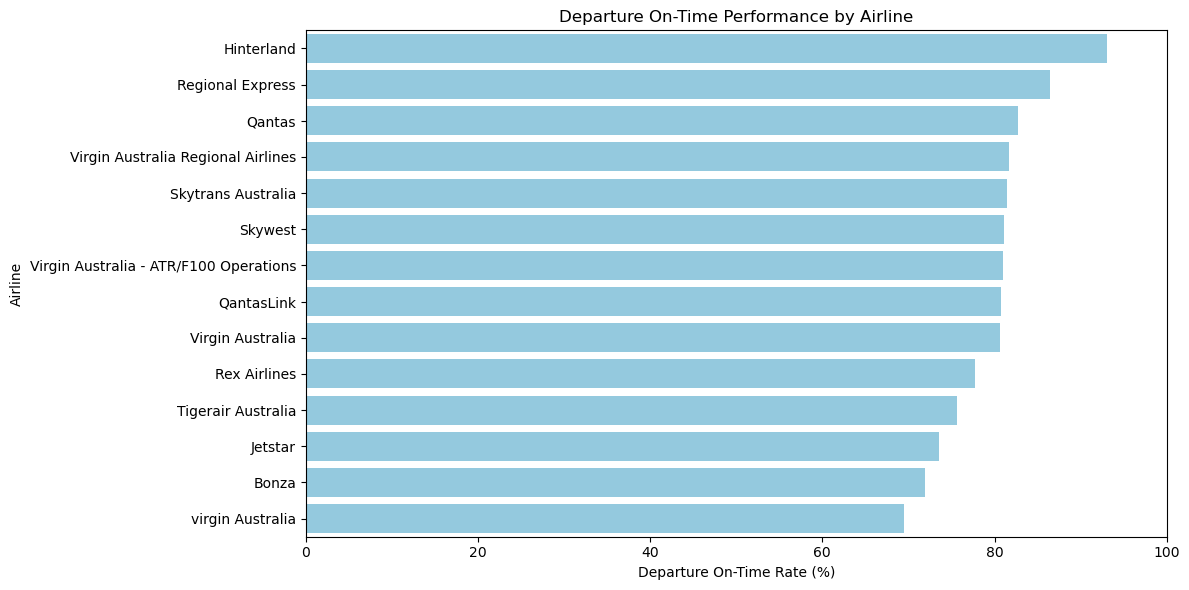

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=airline_analysis,
    x="Departure On-Time Rate (%)",
    y="Airline",
    color="skyblue"
)

plt.title("Departure On-Time Performance by Airline")
plt.xlabel("Departure On-Time Rate (%)")
plt.ylabel("Airline")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

Chart interpretation:

The bar chart compares departure punctuality across airlines. Airlines with longer bars have higher on-time departure percentages, while shorter bars indicate comparatively lower punctuality.

4.2: Chart 2 – Monthly Flight Delay Trend (Line Chart)

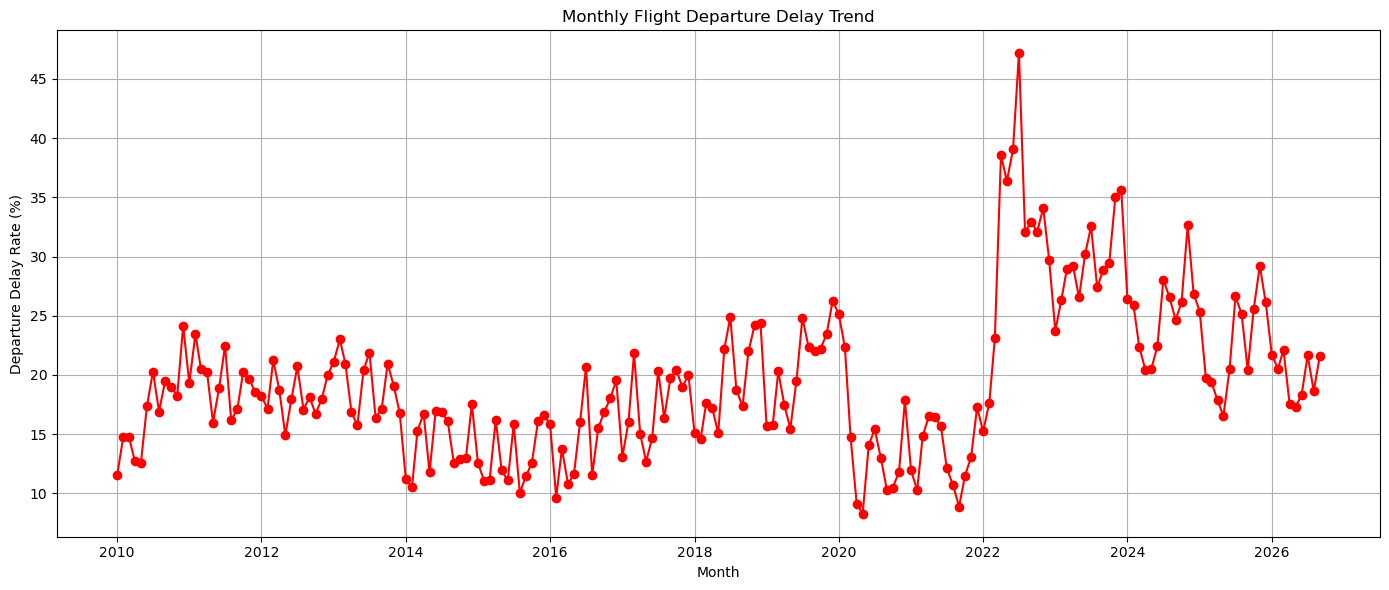

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Delay Rate (%)"],
    marker="o",
    color="red",
    linewidth=1.5
)

plt.title("Monthly Flight Departure Delay Trend")
plt.xlabel("Month")
plt.ylabel("Departure Delay Rate (%)")

plt.grid(True)
plt.tight_layout()
plt.show()

Chart interpretation:

The line chart illustrates changes in departure delay rates over time. Peaks represent months with higher delay percentages, while lower points represent months with better departure punctuality.

4.3: Chart 3 – Distribution of Airline Punctuality (Histogram)

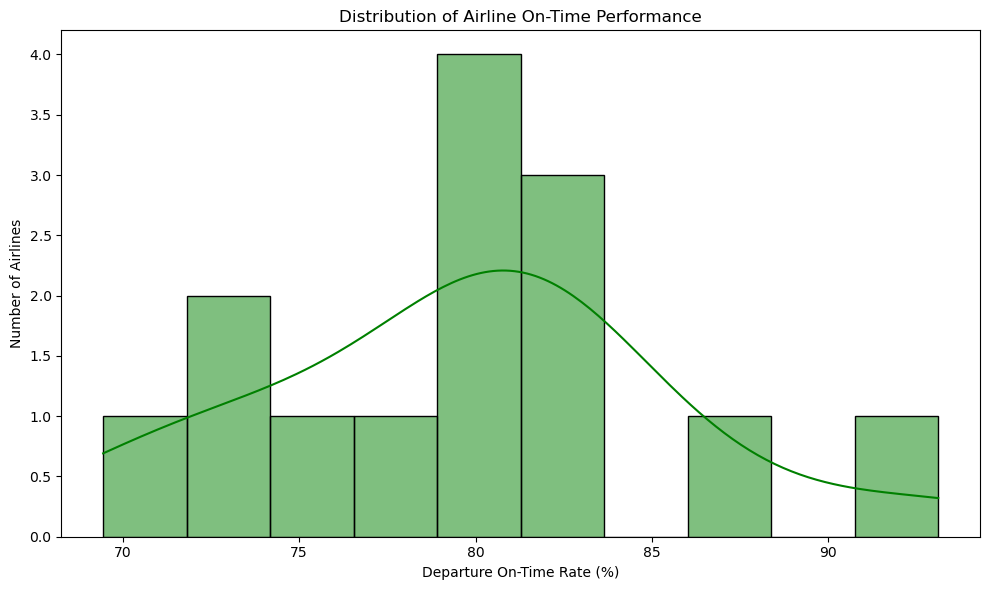

In [30]:
plt.figure(figsize=(10, 6))

sns.histplot(
    airline_analysis["Departure On-Time Rate (%)"].dropna(),
    bins=10,
    kde=True,
    color="green"
)

plt.title("Distribution of Airline On-Time Performance")
plt.xlabel("Departure On-Time Rate (%)")
plt.ylabel("Number of Airlines")

plt.tight_layout()
plt.show()

Chart interpretation:

The histogram shows how airline punctuality rates are distributed. It helps identify the range in which most airlines' on-time performance falls and whether there is considerable variation between airlines.

4.4: Chart 4 – Monthly Delay Distribution (Box Plot)

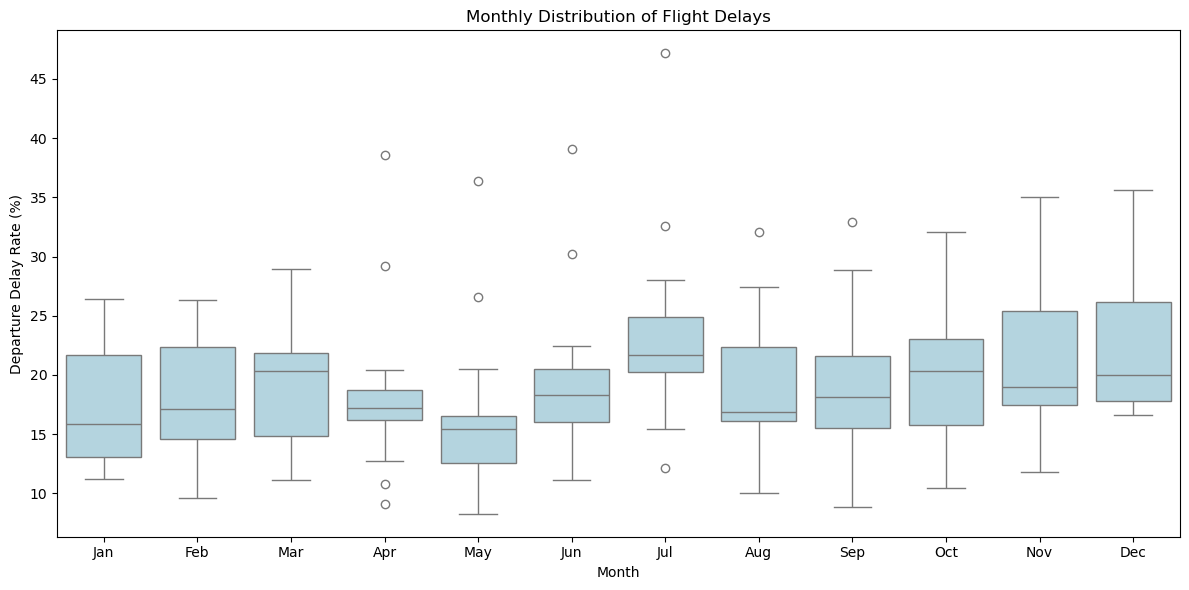

In [31]:
monthly_analysis["Month Name"] = (
    monthly_analysis["Month"].dt.strftime("%b")
)

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=monthly_analysis,
    x="Month Name",
    y="Delay Rate (%)",
    order=month_order,
    color="lightblue"
)

plt.title("Monthly Distribution of Flight Delays")
plt.xlabel("Month")
plt.ylabel("Departure Delay Rate (%)")

plt.tight_layout()
plt.show()

Chart interpretation:

The box plot compares monthly delay distributions across the available years. The median line represents the typical delay rate for each calendar month, while the box and whiskers show variation in the recorded rates

4.5: Chart 5 – Route Punctuality (Horizontal Bar Chart)

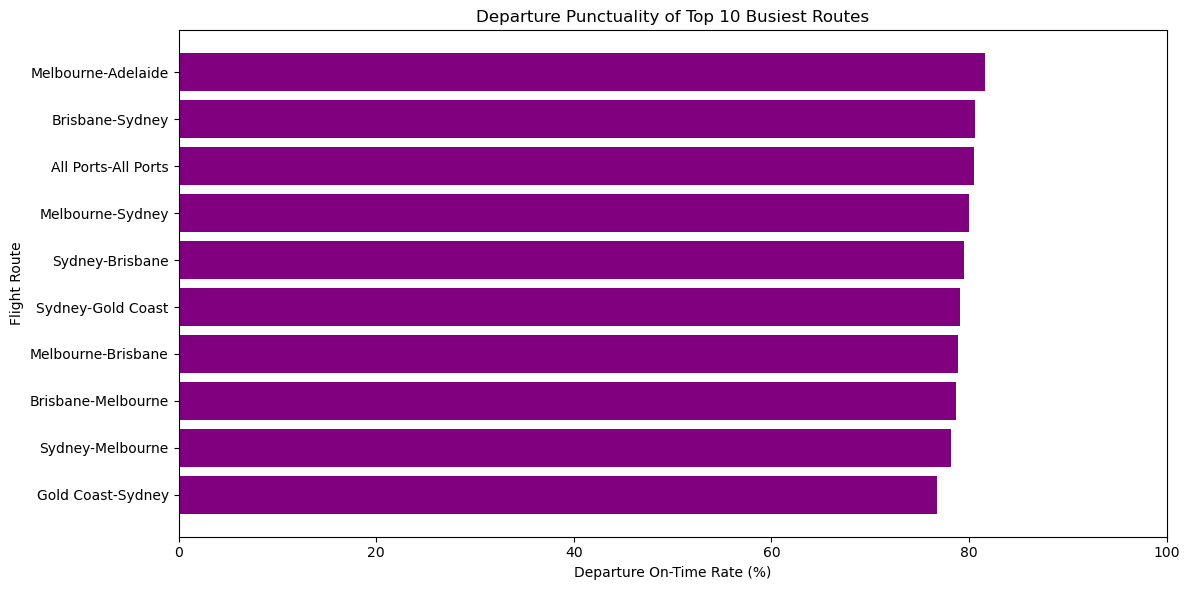

In [33]:
top_routes = route_analysis.sort_values(
    by="Sectors Flown",
    ascending=False
).head(10)

top_routes = top_routes.sort_values(
    by="On-Time Rate (%)"
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_routes["Route"],
    top_routes["On-Time Rate (%)"],
    color="purple"
)

plt.title("Departure Punctuality of Top 10 Busiest Routes")
plt.xlabel("Departure On-Time Rate (%)")
plt.ylabel("Flight Route")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

Chart interpretation:

The chart compares punctuality across the ten busiest routes. Routes with lower percentages may require further investigation to improve operational efficiency and customer satisfaction.